# 02 — Modeling dan evaluasi

Notebook ini mendokumentasikan fine-tuning **DiT-large** menggunakan PyTorch untuk 16 kelas. Arsitektur diinisialisasi dari `microsoft/dit-large`, bobot self-supervised dokumen, lalu seluruh layer dan classifier disesuaikan pada data training kompetisi.

Hasil historis di bawah berasal dari run Kaggle `document-classification-dit-large-v2`; hasil tersebut bukan output training yang baru dijalankan oleh notebook ini. Untuk mengulang training, ubah `RUN_TRAINING` pada bagian 4.

In [1]:
from pathlib import Path
import sys

# Notebook dapat dijalankan dari root repository atau folder notebooks/.
ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").is_file():
    raise FileNotFoundError("Jalankan notebook dari root repository atau folder notebooks/.")
DATA_DIR = ROOT / "data"
sys.path.insert(0, str(ROOT / "src"))

import json
import os
import subprocess
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from IPython.display import display

## 1. Split data

Pisahkan train dan validation sebelum augmentasi menggunakan seed 42, `test_size=0.2`, dan stratifikasi label. Set test kompetisi hanya digunakan untuk prediksi akhir.

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
train_split, validation_split = train_test_split(
    train, test_size=0.2, random_state=42, stratify=train["label"].astype(int)
)
print("Train:", len(train_split), "Validation:", len(validation_split))
comparison = pd.DataFrame({"train_fraction": train_split.label.value_counts(normalize=True),
                           "validation_fraction": validation_split.label.value_counts(normalize=True)}).sort_index()
display(comparison.round(4))

Train: 25602 Validation: 6401


,train_fraction,validation_fraction
label,,
0,0.0629,0.0628
1,0.0626,0.0626
2,0.0629,0.0630
3,0.0632,0.0633
4,0.0627,0.0626
5,0.0633,0.0633
6,0.0619,0.0619
7,0.0616,0.0616
8,0.0623,0.0623


## 2. Pipeline model dan konfigurasi

Implementasi berada di `src/document_classifier/` dan `scripts/train.py`. `DocumentImageDataset` memuat TIFF, mengubahnya menjadi RGB, dan menandai gambar train rusak. Transformasi train menggunakan `RandomAffine` dan penyesuaian brightness/contrast ringan; validation menggunakan resize dan normalisasi tanpa augmentasi acak. Untuk run ini gambar langsung diubah menjadi 224 × 224, tanpa padding rasio aspek.

DiT-large menggunakan classifier 16 kelas, `CrossEntropyLoss` dengan label smoothing, AdamW dengan learning rate terpisah untuk backbone dan classifier, scheduler `ReduceLROnPlateau`, AMP pada CUDA, gradient checkpointing, dan checkpoint berdasarkan validation accuracy terbaik.

In [3]:
CONFIG = {
    "architecture": "dit_large", "image_size": 224, "batch_size": 8,
    "epochs": 8, "seed": 42, "patience": 2,
    "backbone_lr": 1e-5, "classifier_lr": 5e-5,
    "weight_decay": 0.05, "label_smoothing": 0.05,
    "preserve_aspect_ratio": False, "optimizer": "AdamW",
    "pretrained": "microsoft/dit-large (self-supervised IIT-CDIP)",
}
display(pd.Series(CONFIG, name="nilai").to_frame())

,nilai
architecture,dit_large
image_size,224
batch_size,8
epochs,8
seed,42
patience,2
backbone_lr,0.00001
classifier_lr,0.00005
weight_decay,0.05
label_smoothing,0.05


Sumber implementasi yang dapat ditinjau: [model](../src/document_classifier/model.py), [dataset](../src/document_classifier/data.py), [transformasi](../src/document_classifier/transforms.py), dan [training loop](../scripts/train.py). Perintah di bawah memakai implementasi yang sama dengan run historis.

## 3. Menjalankan ulang training (opsional)

Pasang dependensi dari `requirements.txt` dan unduh dataset sesuai README. Training DiT-large membutuhkan GPU dan waktu beberapa jam; bobot pretrained harus dapat diakses dari Hugging Face. Default `False` agar membuka notebook untuk penilaian tidak memulai training baru. Hasil run baru disimpan terpisah di `checkpoint/notebook_dit_large/` dan `checkpoint/notebook_dit_large/reports/`; angka historis di bagian 4 tetap berasal dari run Kaggle.

In [4]:
RUN_TRAINING = False
CHECKPOINT_DIR = ROOT / "checkpoint" / "notebook_dit_large"
RUN_REPORT_DIR = CHECKPOINT_DIR / "reports"
train_command = [
    sys.executable, str(ROOT / "scripts" / "train.py"),
    "--data-dir", str(DATA_DIR), "--checkpoint-dir", str(CHECKPOINT_DIR),
    "--report-dir", str(RUN_REPORT_DIR), "--architecture", "dit_large",
    "--epochs", "8", "--batch-size", "8", "--image-size", "224",
    "--workers", "2", "--seed", "42", "--learning-rate", "1e-5",
    "--label-smoothing", "0.05", "--patience", "2",
]
print("Perintah:", " ".join(train_command))
if RUN_TRAINING:
    import torch
    if not torch.cuda.is_available():
        raise RuntimeError("Aktifkan GPU CUDA sebelum mengulang training DiT-large.")
    env = os.environ.copy()
    env["PYTHONPATH"] = str(ROOT / "src") + os.pathsep + env.get("PYTHONPATH", "")
    env["PYTHONUNBUFFERED"] = "1"
    subprocess.run(train_command, cwd=ROOT, env=env, check=True)
else:
    print("Training baru tidak dijalankan; lihat hasil historis di bawah.")

Perintah: /home/voyager/.t3/projects/sml-cnn-model/.venv/bin/python /home/voyager/.t3/projects/sml-cnn-model/scripts/train.py --data-dir /home/voyager/.t3/projects/sml-cnn-model/data --checkpoint-dir /home/voyager/.t3/projects/sml-cnn-model/checkpoint/notebook_dit_large --report-dir /home/voyager/.t3/projects/sml-cnn-model/checkpoint/notebook_dit_large/reports --architecture dit_large --epochs 8 --batch-size 8 --image-size 224 --workers 2 --seed 42 --learning-rate 1e-5 --label-smoothing 0.05 --patience 2
Training baru tidak dijalankan; lihat hasil historis di bawah.


## 4. Hasil run historis dan interpretasi

File metrik di bawah disalin dari output kernel Kaggle v2. Satu gambar train yang gagal didekode dilewati: 25.601 gambar dipakai untuk training dan seluruh 6.401 gambar dipakai untuk validation. Accuracy adalah jumlah prediksi benar dibagi jumlah sampel yang dievaluasi.

In [5]:
history_path = ROOT / "reports" / "experiments" / "dit_large_v2" / "training_history.csv"
result_path = history_path.with_name("validation_result.json")
history = pd.read_csv(history_path)
result = json.loads(result_path.read_text())
display(history.round(4))
print(f"Best epoch: {result['best_epoch']}; validation accuracy: {result['best_validation_accuracy']:.6f}")
print("Sampel dipakai train/validation:", result['train_samples_used'], result['validation_samples_used'])

,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy
0,1,1.2792,0.6802,0.8211,0.8421
1,2,0.8568,0.8224,0.7372,0.8608
2,3,0.7608,0.8529,0.6976,0.8746
3,4,0.7113,0.8685,0.6829,0.8838
4,5,0.6710,0.8808,0.6691,0.8858
5,6,0.6384,0.8916,0.6620,0.8899
6,7,0.6100,0.9011,0.6557,0.8913
7,8,0.5834,0.9096,0.6448,0.8985


Best epoch: 8; validation accuracy: 0.898453
Sampel dipakai train/validation: 25601 6401


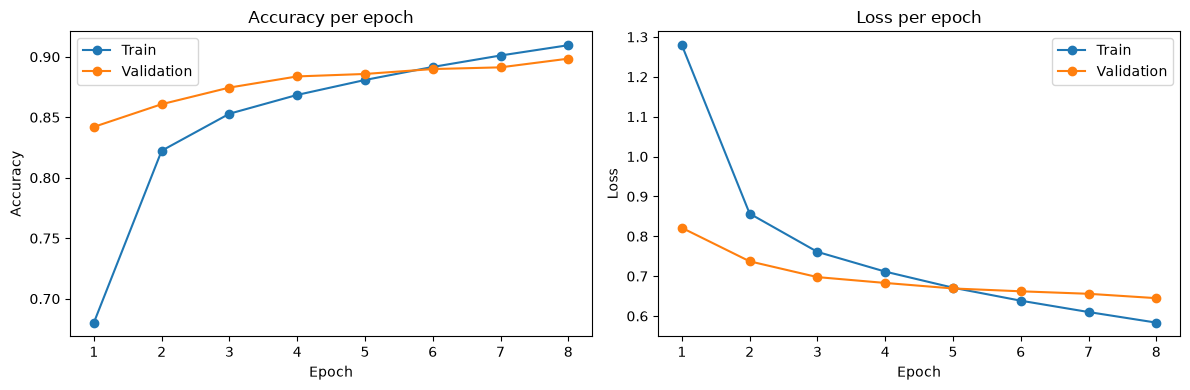

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.epoch, history.train_accuracy, marker="o", label="Train")
axes[0].plot(history.epoch, history.validation_accuracy, marker="o", label="Validation")
axes[0].set(title="Accuracy per epoch", xlabel="Epoch", ylabel="Accuracy")
axes[0].legend()
axes[1].plot(history.epoch, history.train_loss, marker="o", label="Train")
axes[1].plot(history.epoch, history.validation_loss, marker="o", label="Validation")
axes[1].set(title="Loss per epoch", xlabel="Epoch", ylabel="Loss")
axes[1].legend()
plt.tight_layout()
plt.show()

Validation accuracy terbaik **89,845%** diperoleh pada epoch 8. Accuracy train pada epoch tersebut **90,957%**, sekitar 1,11 poin persentase lebih tinggi; ada selisih generalisasi, tetapi hasil ini saja belum menunjukkan penyebabnya. Pengujian beberapa eksperimen pada split validation yang sama juga dapat membuat estimasi optimistis.

Submission checkpoint ini memiliki public score **89,753%** (ref `57871182`). Public score menggunakan subset test yang berbeda dari validation sehingga keduanya tidak dapat dibandingkan sebagai pengukuran pada sampel yang sama. Private score belum diverifikasi dalam laporan ini.